In [1]:
!pip uninstall -y massi
!pip cache purge

Found existing installation: massi 0.1.0
Uninstalling massi-0.1.0:
  Successfully uninstalled massi-0.1.0
Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability --group=sandbox

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 8.1 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file 

In [3]:
# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
    )
    print("Observability is ready")

Observability is ready


In [4]:
from massi.agents.massi import Config

In [5]:
from massi.agents.massi import create_ollama_llm

base_config = Config(**{"model_url": "http://host.docker.internal:11434", "model_name": "granite4:3b"})
base_llm_client=create_ollama_llm(base_config)

In [6]:
from massi.agents.massi import create_openai_llm
openai_config = Config(**{"api_key": os.environ["OPENAI_API_TOKEN"], "model_name": "gpt-5.4-nano"})
openai_llm_client = create_openai_llm(openai_config)

In [7]:
USE_OPEN_AI = True

print(">>> Using OpenAI") if USE_OPEN_AI else print(">>> Using Ollama")
architect_llm = openai_llm_client if USE_OPEN_AI else base_llm_client

>>> Using OpenAI


# Starting the DWC-ready massi

In [8]:
import massi.agents.workflow as mw 

In [9]:
from langchain_core.messages import HumanMessage 

class LocalMetadataArchitect(mw.MetadataArchitect):
    def __init__(self, llm_client):
        self._client = llm_client

    def invoke(self, prompt: str) -> mw.MetadataBlueprint:
        return self._client.with_structured_output(mw.MetadataBlueprint).invoke([HumanMessage(content=prompt)])

In [10]:
resolution_dependencies = mw.Dependencies(architect_client=LocalMetadataArchitect(architect_llm))

In [11]:
goal_workflow = mw._build_goal_resolution_graph(resolution_dependencies)

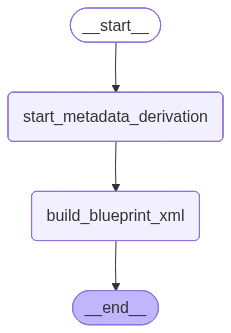

In [12]:
goal_workflow.graph

In [13]:
core_dependencies = mw.Dependencies(
    architect_client=LocalMetadataArchitect(architect_llm), 
    metadata_resolution_subgraph=goal_workflow
)

In [14]:
core_workflow = mw.build_graph(core_dependencies)

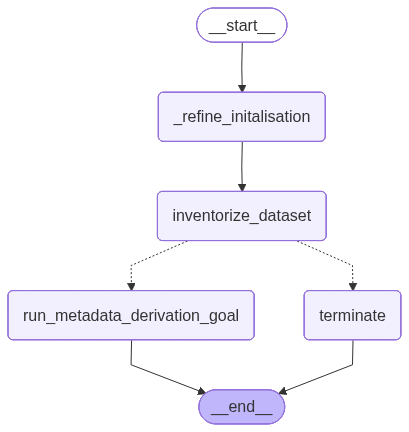

In [15]:
core_workflow.graph

## Inference

In [16]:
import massi.agents.tools as mt

dwc_data_file_metadata_goal: mw.MetadataGoal = {
    "level": mw.MetadataLevel.ITEM,
    "scopes": [mw.MetadataScope.DESCRIPTIVE, mw.MetadataScope.TECHNICAL, mw.MetadataScope.USE],
    "target_filename": "meta.xml",
    # "schema": mt.get_xmlschema_validator("https://dwc.tdwg.org/text/tdwg_dwc_text.xsd"),
    "schema_source": "https://dwc.tdwg.org/text/tdwg_dwc_text.xsd",
    "description": (
        "This metadata file describes the archive and data file structure."
        "A descriptor metafile describes how the files in your archive are organized."
        "It describes the files in the archive and maps each data column to a corresponding standard Darwin Core or Extension term."
        "The metafile is a relatively simple XML file format."
    ),
    "get_architect_agent_prompt_key": "darwin_core",
}

In [17]:
import random
thread_config = {"configurable": {"thread_id": str(random.randint(1, 100))}}

In [18]:
base_state: mw.MassiCoreState = {
    "settings": {
        "runtime_config": {
            "working_directory": "./dwc_data/masked-doi-10.34894-72gq4c", 
            "output_directory": "./dwc_data/masked-doi-10.34894-72gq4c"
        },
        "execution_mode": mw.MassiExecutionMode.HUMAN_INQUIRY
    },
    "goals": [dwc_data_file_metadata_goal]
}

In [19]:
outcome = core_workflow.graph.invoke(base_state, thread_config)

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [20]:
import pprint 

In [26]:
print(outcome["resolutions"][0]["architect_blueprint"]["xml_blueprint"])

<?xml version="1.0" encoding="UTF-8"?>
<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="{{GAP_001:URI:METADATA_LOCATION}}">
  <core rowType="http://rs.tdwg.org/dwc/terms/eventID" fieldsTerminatedBy="," fieldsEnclosedBy="&quot;" ignoreHeaderLines="1">
    <files>
      <location>budburst_event.csv</location>
    </files>
    <id index="1" />

    <!-- core fields -->
    <field index="0" term="{{GAP_002:URI:eventID_OR_empty_header}}" />
    <field index="2" term="http://rs.tdwg.org/dwc/terms/parentEventID" />
    <field index="3" term="http://rs.tdwg.org/dwc/terms/samplingProtocol" />
    <field index="4" term="http://rs.tdwg.org/dwc/terms/sampleSizeValue" />
    <field index="5" term="http://rs.tdwg.org/dwc/terms/sampleSizeUnit" />
    <field index="6" term="http://rs.tdwg.org/dwc/terms/eventDate" />
    <field index="7" term="http://rs.tdwg.org/dwc/terms/year" />
    <field index="8" term="http://rs.tdwg.org/dwc/terms/month" />
    <field index="9" term="http://rs.tdwg.org/dwc/